# 01 · ข้อมูล — จากไฟล์ดิบถึงเมทริกซ์วิเคราะห์

| ขั้น | ทำอะไร | ตรวจอะไร |
| --- | --- | --- |
| 1 | สำรวจไฟล์ดิบ 18 ไฟล์ | ครบและขนาดสมเหตุสมผล |
| 2 | ประกอบ WNPMI จาก U850 สองกล่อง | วงรอบรายเดือนต้องบวกสุดช่วงมรสุม ก.ค.–ก.ย. |
| 3 | หาหน้าต่างเวลาที่ทุกดัชนีทับกัน | ต้องได้ 1951.04–2023.04 |
| 4 | จัดทุกอนุกรมลงกริดรายเดือนร่วม | ข้อมูลต้องไม่หายเกินอัตราที่ MANIFEST บอก |
| 5 | ตัดแนวโน้ม + ฤดูกาล | สัมประสิทธิ์ต้องไม่ขึ้นกับช่องว่าง |
| 6 | เติมช่องว่าง + เก็บ mask | mask ต้องตรงตำแหน่งที่เติมจริง |
| 7 | เทียบกับ `series.npz` ที่สคริปต์สร้าง | ต้องเหมือนกันทุก bit |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from wtc.loaders import read_psmsl, read_noaa_index, read_uhslc, read_wnpmi
from wtc.preprocess import align, common_window, detrend_deseason, fill_gaps, MAX_INTERP_MONTHS
from wtc.plotting import use_thai_font, plot_series

RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "figures"
print("ฟอนต์ที่ใช้ในรูป:", use_thai_font())
print("รากโปรเจกต์:", ROOT)

ฟอนต์ที่ใช้ในรูป: Noto Sans Thai
รากโปรเจกต์: /home/panguin/Projects/DSP/Project-SeaLevelWTC


## 1. ไฟล์ดิบที่มี

In [2]:
rows = []
for f in sorted(RAW.rglob("*")):
    if f.is_file():
        rows.append((str(f.relative_to(RAW)), f.stat().st_size))
for name, size in rows:
    print(f"  {name:42s} {size:>12,} B")
print(f"\nรวม {len(rows)} ไฟล์")

sys.path.insert(0, str(ROOT / "scripts"))
from fetch_data import ALL, U850
expected = set(ALL) | set(U850)
have = {name for name, _ in rows}
assert expected <= have, f"ไฟล์ขาด: {sorted(expected - have)} — รัน scripts/fetch_data.py ก่อน"
print(f"✅ ครบทุกไฟล์ที่ fetch_data.py ประกาศ ({len(expected)} ไฟล์)")

  indices/amo.data                                  8,817 B
  indices/dmi.data                                 19,861 B
  indices/nao.data                                  7,218 B
  indices/nino34.data                               8,362 B
  indices/pdo.data                                  7,514 B
  indices/soi.data                                  7,139 B
  indices/tpi.data                                 22,089 B
  indices/u850_box_north.data                       9,070 B
  indices/u850_box_south.data                       9,070 B
  indices/whwp.data                                 8,469 B
  psmsl/fort_phrachula_chomklao_annual.rlrdata        1,615 B
  psmsl/fort_phrachula_chomklao_monthly.rlrdata       26,520 B
  psmsl/ko_lak_annual.rlrdata                       1,615 B
  psmsl/ko_lak_monthly.rlrdata                     26,520 B
  psmsl/ko_taphao_noi_annual.rlrdata                1,615 B
  psmsl/ko_taphao_noi_monthly.rlrdata              26,520 B
  uhslc/ko_lak_hourly.csv          

## 2. WNPMI — ดัชนีเดียวของโปรเจกต์ที่ต้องประกอบเอง

$$\text{WNPMI} = \overline{U_{850}}\big|_{5\text{–}15^\circ N,\,100\text{–}130^\circ E}
- \overline{U_{850}}\big|_{20\text{–}30^\circ N,\,110\text{–}140^\circ E}$$

In [3]:
t_s, v_s = read_noaa_index(RAW / "indices" / "u850_box_south.data")
t_n, v_n = read_noaa_index(RAW / "indices" / "u850_box_north.data")
t_w, v_w = read_wnpmi(RAW / "indices")

month = np.round((t_w % 1) * 12 - 0.5).astype(int)
clim = np.array([np.nanmean(v_w[month == m]) for m in range(12)])
peak = int(np.argmax(clim)) + 1
print("วงรอบรายเดือนของ WNPMI (m/s):")
for m, c in enumerate(clim, 1):
    print(f"   เดือน {m:2d}: {c:+6.2f}  {'#' * int(abs(c) * 3)}")
print(f"\nเดือนที่ค่าสูงสุด = {peak}")
assert peak in (7, 8, 9), "ค่าสูงสุดไม่อยู่ช่วงมรสุม — น่าจะสลับกล่องเหนือ/ใต้กัน" 

วงรอบรายเดือนของ WNPMI (m/s):
   เดือน  1:  -7.44  ######################
   เดือน  2:  -7.61  ######################
   เดือน  3:  -7.13  #####################
   เดือน  4:  -5.28  ###############
   เดือน  5:  -2.19  ######
   เดือน  6:  +0.45  #
   เดือน  7:  +3.99  ###########
   เดือน  8:  +6.20  ##################
   เดือน  9:  +6.01  ##################
   เดือน 10:  +3.19  #########
   เดือน 11:  -1.46  ####
   เดือน 12:  -5.28  ###############

เดือนที่ค่าสูงสุด = 8


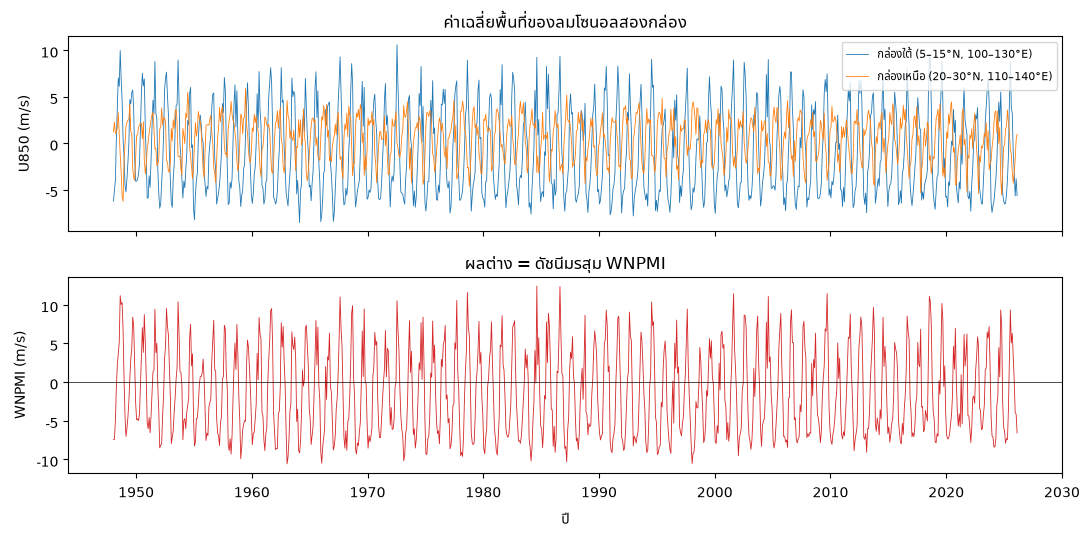

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(t_s, v_s, lw=0.6, label="กล่องใต้ (5–15°N, 100–130°E)")
ax[0].plot(t_n, v_n, lw=0.6, label="กล่องเหนือ (20–30°N, 110–140°E)")
ax[0].set_ylabel("U850 (m/s)"); ax[0].legend(fontsize=8); ax[0].set_title("ค่าเฉลี่ยพื้นที่ของลมโซนอลสองกล่อง")
ax[1].plot(t_w, v_w, lw=0.6, color="C3")
ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_ylabel("WNPMI (m/s)"); ax[1].set_xlabel("ปี"); ax[1].set_title("ผลต่าง = ดัชนีมรสุม WNPMI")
fig.tight_layout()
FIGURES.mkdir(exist_ok=True)
fig.savefig(FIGURES / "w1-wnpmi-construction.png", dpi=130)
plt.show()

## 3. หน้าต่างเวลาที่ทุกดัชนีทับกัน

In [5]:
INDEX_FILES = ["nino34", "soi", "pdo", "amo", "nao", "tpi", "dmi"]
STATIONS = {"ko_lak": "KO LAK (อ่าวไทย)",
            "ko_taphao_noi": "KO TAPHAO NOI (อันดามัน)",
            "fort_phrachula_chomklao": "FORT PHRACHULA (อ่าวไทยตอนบน)"}

raw = {k: read_psmsl(RAW / "psmsl" / f"{k}_monthly.rlrdata") for k in STATIONS}

from wtc.qc import apply_exclusions, PSMSL_EXCLUDE
for k in STATIONS:
    t_k, v_k = raw[k]
    v_k, cut = apply_exclusions(k, t_k, v_k)
    raw[k] = (t_k, v_k)
    for m in cut:
        print(f"ตัด {k} {m}: {PSMSL_EXCLUDE[k][m][:70]}…")
raw |= {n: read_noaa_index(RAW / "indices" / f"{n}.data") for n in INDEX_FILES}
raw["wnpmi"] = read_wnpmi(RAW / "indices")
INDEX_NAMES = INDEX_FILES + ["wnpmi"]

for n in INDEX_NAMES:
    t, v = raw[n]
    g = np.isfinite(v)
    print(f"  {n:8s} {t[g][0]:9.3f} – {t[g][-1]:9.3f}   ({int(g.sum())} เดือนที่มีค่า)")

start, stop = common_window({n: raw[n] for n in INDEX_NAMES})
print(f"\n🔴 หน้าต่างร่วม = {start:.3f} – {stop:.3f}  ({(stop-start):.1f} ปี)")
assert abs(start - 1951.0417) < 1e-3 and abs(stop - 2023.0417) < 1e-3, \
    "หน้าต่างเปลี่ยนไปจากที่บันทึกไว้ — แหล่งข้อมูลอัปเดต ต้องอ่านก่อนเดินต่อ" 

ตัด ko_taphao_noi 1985-10: PSMSL 7469 mm ขณะที่เดือนข้างเคียง 7131/7186 (กระโดด ~+300 แล้วกลับ) ·…
ตัด ko_taphao_noi 1987-06: PSMSL 7498 mm ขณะที่เดือนข้างเคียง 7150/7248 · UHSLC สองผลิตภัณฑ์ต่อเน…
  nino34    1948.042 –  2026.625   (944 เดือนที่มีค่า)
  soi       1951.042 –  2026.542   (907 เดือนที่มีค่า)
  pdo       1948.042 –  2025.958   (936 เดือนที่มีค่า)
  amo       1948.042 –  2023.042   (901 เดือนที่มีค่า)
  nao       1950.042 –  2026.542   (919 เดือนที่มีค่า)
  tpi       1854.042 –  2026.625   (2072 เดือนที่มีค่า)
  dmi       1870.042 –  2026.375   (1877 เดือนที่มีค่า)
  wnpmi     1948.042 –  2026.125   (938 เดือนที่มีค่า)

🔴 หน้าต่างร่วม = 1951.042 – 2023.042  (72.0 ปี)


## 4. จัดลงกริดรายเดือนร่วม

In [6]:
grid, aligned = align(raw, start, stop)
n = len(grid)
print(f"กริด {n} จุด: {grid[0]:.4f} – {grid[-1]:.4f}  (ห่างกัน {np.diff(grid).mean():.6f} ปี = 1 เดือน)")
print()
print(f"  {'อนุกรม':32s} {'จับลงกริดได้':>12s} {'หาย':>8s}")
for name in list(STATIONS) + INDEX_NAMES:
    v = aligned[name]
    ok = int(np.isfinite(v).sum())
    print(f"  {STATIONS.get(name, name):32s} {ok:12d} {1 - ok/n:8.1%}")
    assert ok / n >= (0.999 if name in INDEX_NAMES else 0.90), f"{name} หายมากผิดปกติ" 

กริด 865 จุด: 1951.0417 – 2023.0417  (ห่างกัน 0.083333 ปี = 1 เดือน)

  อนุกรม                           จับลงกริดได้      หาย
  KO LAK (อ่าวไทย)                          838     3.1%
  KO TAPHAO NOI (อันดามัน)                  807     6.7%
  FORT PHRACHULA (อ่าวไทยตอนบน)             820     5.2%
  nino34                                    865     0.0%
  soi                                       865     0.0%
  pdo                                       865     0.0%
  amo                                       865     0.0%
  nao                                       865     0.0%
  tpi                                       865     0.0%
  dmi                                       865     0.0%
  wnpmi                                     865     0.0%


## 5. ตัดแนวโน้มและฤดูกาล

In [7]:
series, info_all = {}, {}
print(f"  {'อนุกรม':32s} {'แนวโน้ม/ปี':>11s} {'วงรอบปี':>9s} {'%แนวโน้ม':>9s} {'%ฤดูกาล':>9s}")
print("  " + "-" * 74)
for name in list(STATIONS) + INDEX_NAMES:
    z, info = detrend_deseason(grid, aligned[name])
    series[name], info_all[name] = z, info
    print(f"  {STATIONS.get(name, name):32s} {info.slope:11.3f} {info.annual_amp:9.2f} "
          f"{info.frac_trend:8.1%} {info.frac_season:9.1%}")

  อนุกรม                            แนวโน้ม/ปี   วงรอบปี  %แนวโน้ม   %ฤดูกาล
  --------------------------------------------------------------------------
  KO LAK (อ่าวไทย)                       1.766    212.63     4.9%     81.2%
  KO TAPHAO NOI (อันดามัน)               4.041     86.76    28.4%     29.8%
  FORT PHRACHULA (อ่าวไทยตอนบน)         15.641    150.38    83.9%     58.4%
  nino34                                 0.006      0.03     3.0%      0.1%
  soi                                    0.002      0.10     0.0%      0.2%
  pdo                                    0.009      0.21     3.0%      1.9%
  amo                                    0.003      0.04     8.8%      1.9%
  nao                                    0.004      0.15     0.6%      2.2%
  tpi                                   -0.002      0.04     0.3%      0.1%
  dmi                                    0.005      0.07    10.3%      2.7%
  wnpmi                                 -0.001      7.05    -0.0%     83.5%


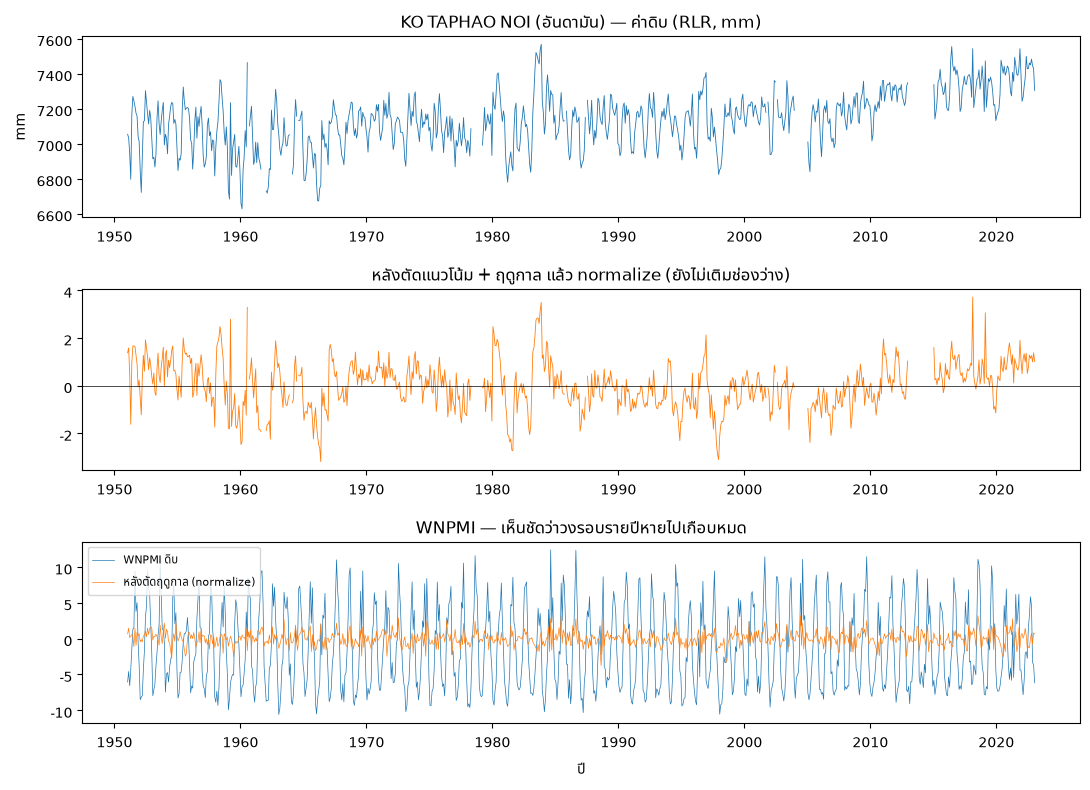

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8))
key = "ko_taphao_noi"
axes[0].plot(grid, aligned[key], lw=0.6)
axes[0].set_title(f"{STATIONS[key]} — ค่าดิบ (RLR, mm)"); axes[0].set_ylabel("mm")
axes[1].plot(grid, series[key], lw=0.6, color="C1")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_title("หลังตัดแนวโน้ม + ฤดูกาล แล้ว normalize (ยังไม่เติมช่องว่าง)")
axes[2].plot(grid, aligned["wnpmi"], lw=0.5, label="WNPMI ดิบ")
axes[2].plot(grid, series["wnpmi"], lw=0.5, label="หลังตัดฤดูกาล (normalize)")
axes[2].set_title("WNPMI — เห็นชัดว่าวงรอบรายปีหายไปเกือบหมด")
axes[2].legend(fontsize=8); axes[2].set_xlabel("ปี")
fig.tight_layout(); fig.savefig(FIGURES / "w1-detrend-deseason.png", dpi=130); plt.show()

## 6. เติมช่องว่าง — และพก mask ไปด้วยตลอดสาย

| ความยาวช่องว่าง | ทำอย่างไร | เหตุผล |
| --- | --- | --- |
| ≤ 3 เดือน | interp เชิงเส้นบน anomaly | anomaly ของระดับน้ำทะเลสหสัมพันธ์สูงที่ lag 1–3 เดือน |
| > 3 เดือน | **เติม 0** | 0 บน anomaly = ค่าปกติทางภูมิอากาศ · การ interp ข้ามช่องยาวจะสร้าง

  KO LAK (อ่าวไทย)                 เติม  27 จุด ( 3.1%) · ช่องว่างยาวสุด 12 เดือน
  KO TAPHAO NOI (อันดามัน)         เติม  58 จุด ( 6.7%) · ช่องว่างยาวสุด 24 เดือน
  FORT PHRACHULA (อ่าวไทยตอนบน)    เติม  45 จุด ( 5.2%) · ช่องว่างยาวสุด 24 เดือน


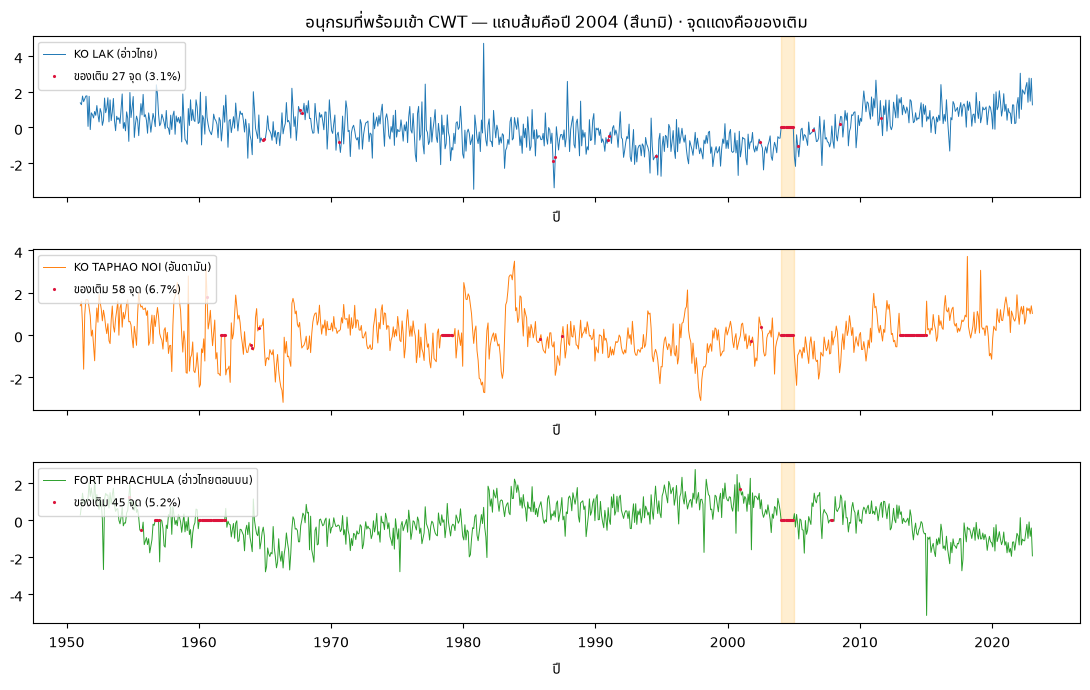

In [9]:
filled, masks = {}, {}
for name, z in series.items():
    filled[name], masks[name] = fill_gaps(z, MAX_INTERP_MONTHS)
    assert np.isfinite(filled[name]).all()
    assert np.array_equal(masks[name], ~np.isfinite(z)), "mask ไม่ตรงกับตำแหน่งที่หายจริง"

for name in STATIONS:
    m = masks[name]
    runs = np.diff(np.flatnonzero(np.diff(np.r_[0, m.view(np.int8), 0])))[::2]
    print(f"  {STATIONS[name]:32s} เติม {m.sum():3d} จุด ({m.mean():5.1%}) · "
          f"ช่องว่างยาวสุด {runs.max() if len(runs) else 0} เดือน")

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, name in zip(axes, STATIONS):
    plot_series(ax, grid, filled[name], masks[name], label=STATIONS[name],
                color=f"C{list(STATIONS).index(name)}")
    ax.axvspan(2004, 2005, color="orange", alpha=0.18)
axes[0].set_title("อนุกรมที่พร้อมเข้า CWT — แถบส้มคือปี 2004 (สึนามิ) · จุดแดงคือของเติม")
fig.tight_layout(); fig.savefig(FIGURES / "w1-filled-series.png", dpi=130); plt.show()

## 7. ด่านสุดท้าย — ต้องได้ผลเดียวกับสคริปต์

In [10]:
d = np.load(ROOT / "data" / "processed" / "series.npz", allow_pickle=True)
y_names, x_names = [str(s) for s in d["y_names"]], [str(s) for s in d["x_names"]]
assert np.allclose(d["t"], grid)
for i, k in enumerate(y_names):
    assert np.allclose(d["Y"][i], filled[k]), k
    assert np.array_equal(d["Y_fill"][i], masks[k]), k
for i, k in enumerate(x_names):
    assert np.allclose(d["X"][i], filled[k]), k
    assert np.array_equal(d["X_fill"][i], masks[k]), k
meta = json.loads(str(d["meta"]))
print("✅ โน้ตบุ๊กกับสคริปต์ให้ผลตรงกันทุกค่า")
print(f"   Y {d['Y'].shape} = {y_names}")
print(f"   X {d['X'].shape} = {x_names}")
print(f"   หน้าต่าง {meta['window'][0]:.4f}–{meta['window'][1]:.4f} · dt = {meta['dt']:.6f} ปี")

✅ โน้ตบุ๊กกับสคริปต์ให้ผลตรงกันทุกค่า
   Y (3, 865) = ['ko_lak', 'ko_taphao_noi', 'fort_phrachula_chomklao']
   X (8, 865) = ['nino34', 'soi', 'pdo', 'amo', 'nao', 'tpi', 'dmi', 'wnpmi']
   หน้าต่าง 1951.0417–2023.0417 · dt = 0.083333 ปี


## สรุปของโน้ตบุ๊กนี้